<h1>CME538 - Introduction to Data Science</h1>
<h2>Lecture 5.2 - Loss Functions</h2>
<p>A loss function defines which prediction errors matter. The existing tips examples compare constant predictions, then the extensions inspect individual contributions and a constructed repair-planning decision.</p><p>Central question: how does the choice of loss change the best constant prediction?</p><p>After this notebook, you should calculate absolute and squared error, distinguish pointwise from average loss, find a grid minimum, and explain why the error costs affect the fitted value.</p>
<a id="lecture-structure"></a><h3>Lecture Structure</h3><ol><li><a href="#section1">Import Tips Data</a></li><li><a href="#section2">Absolute Loss</a></li><li><a href="#section3">Squared Loss</a></li><li><a href="#section4">Squared Loss vs Absolute Loss</a></li><li><a href="#section5">Average Loss</a></li><li><a href="#section6">Brute Force Optimization</a></li></ol>
<p><a href="#lecture-summary">Lecture summary</a></p>
<h3>Optional extensions</h3><ol start="7"><li><a href="#section7">Individual errors and the loss minimum</a></li><li><a href="#section8">Sensitivity to an extreme observation</a></li><li><a href="#section9">Error costs in repair planning</a></li></ol>
<p>Run Setup Notebook first, then run the sections in order. The main section numbers match the slide handoffs.</p>
<h3>Sources and documentation</h3><p><a href="../slides/week5_lecture2.pptx">Lecture slides</a> | <a href="DATA_SOURCES.html">Dataset sources and fields</a> | <a href="https://numpy.org/doc/stable/reference/generated/numpy.mean.html">NumPy means</a></p>

<h2>Setup Notebook</h2><p>The course environment supplies NumPy, pandas, Matplotlib and Seaborn. All datasets are local. Plot layouts live in <a href="utils.py">utils.py</a>. Loss functions, gradients, parameter updates and optimization loops remain visible below.</p>

In [1]:
import numpy as np
import pandas as pd

import utils

%matplotlib inline
RANDOM_STATE = 538
utils.configure_plots()
pd.set_option('display.max_columns', 8)
pd.set_option('display.max_rows', 10)

<a id="Import-Tips-Data"></a>
<a id="section1"></a><h2>1. Import Tips Data</h2><p>Question: what does one restaurant bill tell us about tip percentages?</p>

<h3>Load the same classroom sample</h3><p>The local tips table contains one row per restaurant bill. Keep the first 243 rows, matching the existing slide examples. This sample describes one restaurant context rather than all restaurant customers.</p>

In [2]:
tips = pd.read_csv('tips.csv').iloc[:-1].copy()
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<h3>Calculate the response</h3><p>Divide the tip by the bill and multiply by 100. A constant model predicts the same percentage for every bill.</p>

In [3]:
tips['tip_pct'] = tips['tip'] / tips['total_bill'] * 100
tips[['total_bill', 'tip', 'tip_pct']].head()

,total_bill,tip,tip_pct
0,16.99,1.01,5.944673
1,10.34,1.66,16.054159
2,21.01,3.50,16.658734
3,23.68,3.31,13.978041
4,24.59,3.61,14.680765


<h3>Inspect the distribution</h3><p>A rug plot marks every observed percentage. The histogram and smooth density show the distribution, while the reference lines locate the mean and median.</p>

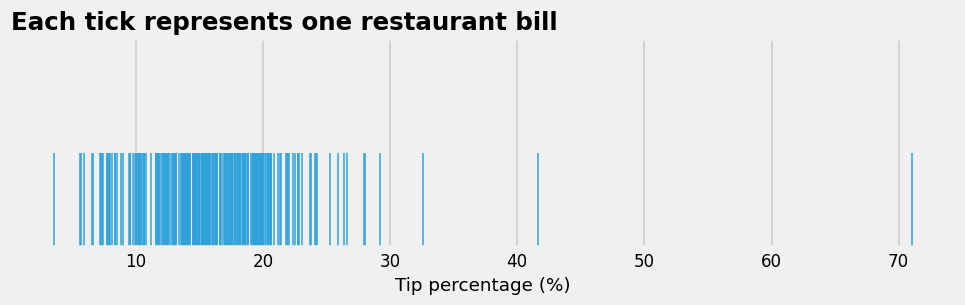

In [4]:
utils.plot_tips(tips['tip_pct'], rug_only=True)

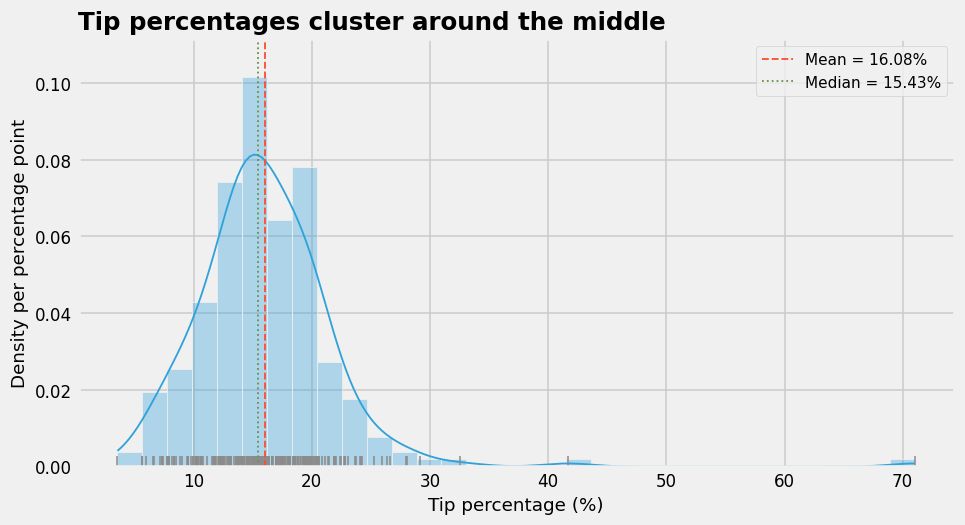

In [5]:
mean = tips['tip_pct'].mean()
median = tips['tip_pct'].median()
utils.plot_tips(tips['tip_pct'], mean=mean, median=median)

<p>The long upper tail moves the mean above the median. Both summaries use the same observations.</p>

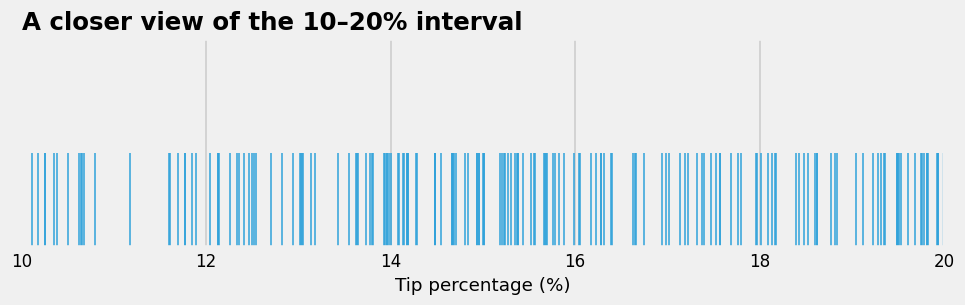

In [6]:
utils.plot_tips(tips['tip_pct'], rug_only=True, zoom=True)

<p>Takeaway: A constant prediction summarizes variation across bills. Its preferred value depends on the loss used to score errors.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="Absolute-Loss"></a>
<a id="section2"></a><h2>2. Absolute Loss</h2><p>Question: how does absolute loss change as a prediction moves away from the observation?</p>

<h3>Calculate one-observation loss</h3><p>Hold the observed tip at 15%. The absolute error is the distance between the observation and each candidate prediction, measured in percentage points.</p>

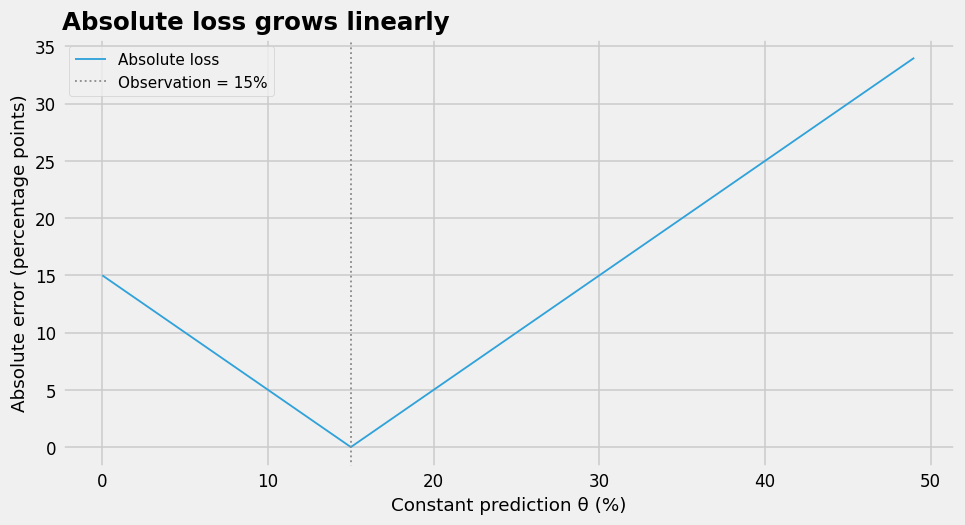

In [7]:
observation = 15
thetas = range(50)
absolute_errors = [np.abs(observation - theta) for theta in thetas]
utils.plot_point_losses(thetas, observation, absolute=absolute_errors)

<p>Takeaway: Absolute loss gives equal penalties to errors of equal magnitude above and below the observation.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="Squared-Loss"></a>
<a id="section3"></a><h2>3. Squared Loss</h2><p>Question: how does squaring the error change the penalty?</p>

<h3>Square the same residuals</h3><p>Keep the same observation and candidates. Squared error has units of percentage points squared. Doubling an error multiplies this penalty by four.</p>

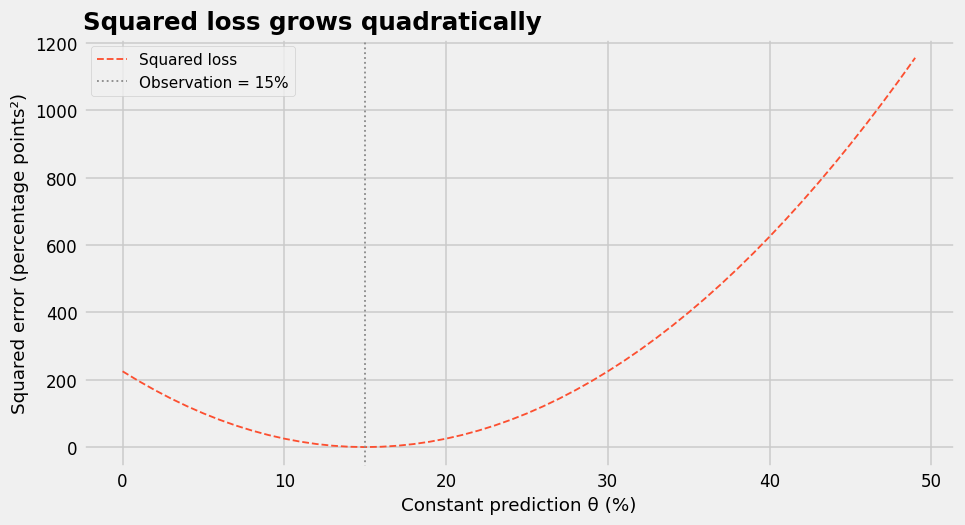

In [8]:
observation = 15
thetas = range(50)
squared_errors = [(observation - theta)**2 for theta in thetas]
utils.plot_point_losses(thetas, observation, squared=squared_errors)

<p>Takeaway: Squared loss assigns increasing weight to larger residuals.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="Squared-Loss-vs-Absolute-Loss"></a>
<a id="section4"></a><h2>4. Squared Loss vs Absolute Loss</h2><p>Question: where do the shapes of the two losses differ?</p>

<h3>Compare near the observation</h3><p>The first view focuses on small losses. The curves use different units, so their numerical heights do not establish which loss is better. Their shapes show how penalties grow.</p>

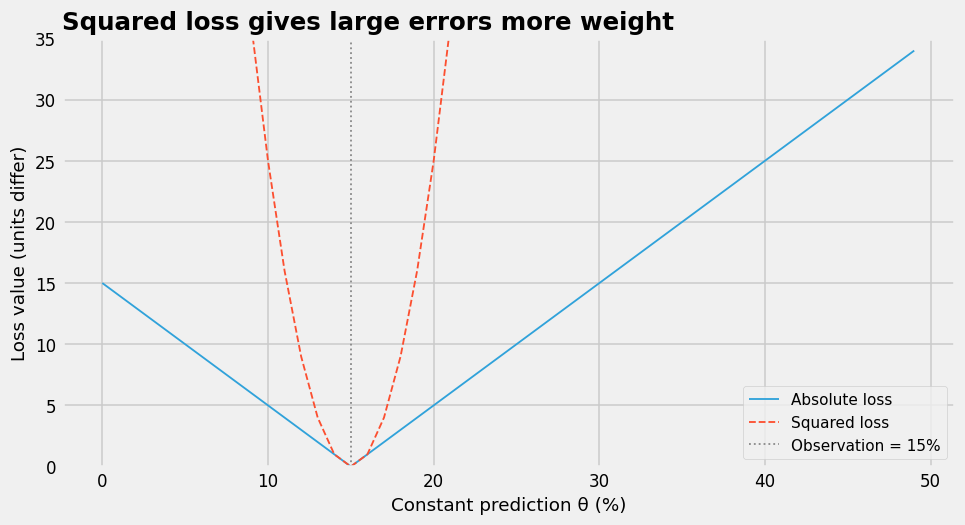

In [9]:
absolute_errors = [np.abs(observation - theta) for theta in thetas]
squared_errors = [(observation - theta)**2 for theta in thetas]
utils.plot_point_losses(thetas, observation, absolute_errors, squared_errors)

<h3>Expand the loss scale</h3><p>The second view retains the same values and expands the vertical range. Large errors dominate the squared-loss curve.</p>

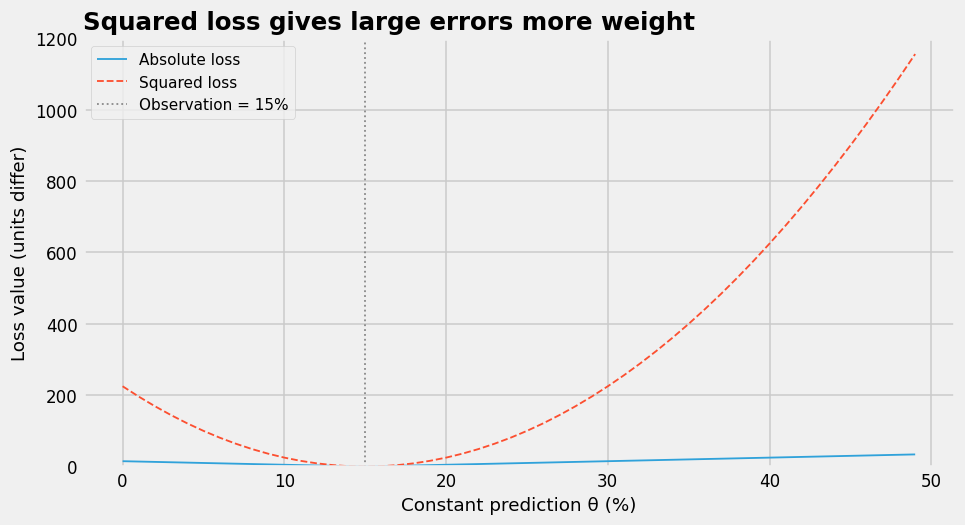

In [10]:
utils.plot_point_losses(thetas, observation, absolute_errors, squared_errors, wide=True)

<p>Takeaway: Choose a loss from the consequences of errors and the data context. Absolute loss reduces the relative influence of extreme residuals without ignoring those observations.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="Average-Loss"></a>
<a id="section5"></a><h2>5. Average Loss</h2><p>Question: how do we evaluate one constant prediction against every bill?</p>

<h3>Define the objective</h3><p>Average the per-observation penalties. Mean absolute error (MAE) retains the response units. Mean squared error (MSE) has squared response units. These functions and the search remain visible because they define fitting.</p>

In [11]:
def absolute_loss(y, theta):
    """Mean absolute error for a constant prediction."""
    return np.mean(np.abs(y - theta))

def squared_loss(y, theta):
    """Mean squared error for a constant prediction."""
    return np.mean((y - theta)**2)

<p>Evaluate the loss at every candidate and select the smallest value. The search returns the best candidate on the supplied grid, which need not be the exact minimum over all real values.</p>

In [12]:
def brute_force_optimize(loss_func, dataset, thetas):
    losses = [loss_func(dataset, theta) for theta in thetas]
    best = np.argmin(losses)
    return {'optimum_theta': thetas[best],
            'optimum_loss': losses[best],
            'thetas': thetas, 'losses': losses}

<h3>Average absolute loss</h3><p>Try candidates spaced five percentage points apart. Each dot scores one candidate against all 243 bills.</p>

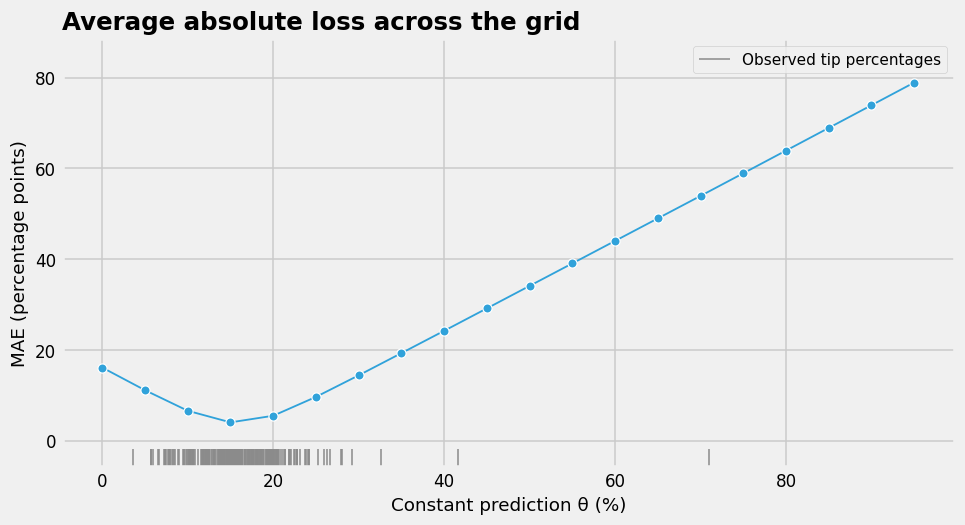

In [13]:
absolute_loss_optimum = brute_force_optimize(
    absolute_loss, tips['tip_pct'].to_numpy(), np.arange(0, 100, 5))
utils.plot_average_loss(tips['tip_pct'], absolute_loss_optimum, squared=False, coarse=True)

<h3>Average squared loss</h3><p>Try candidates spaced five percentage points apart. Each dot scores one candidate against all 243 bills.</p>

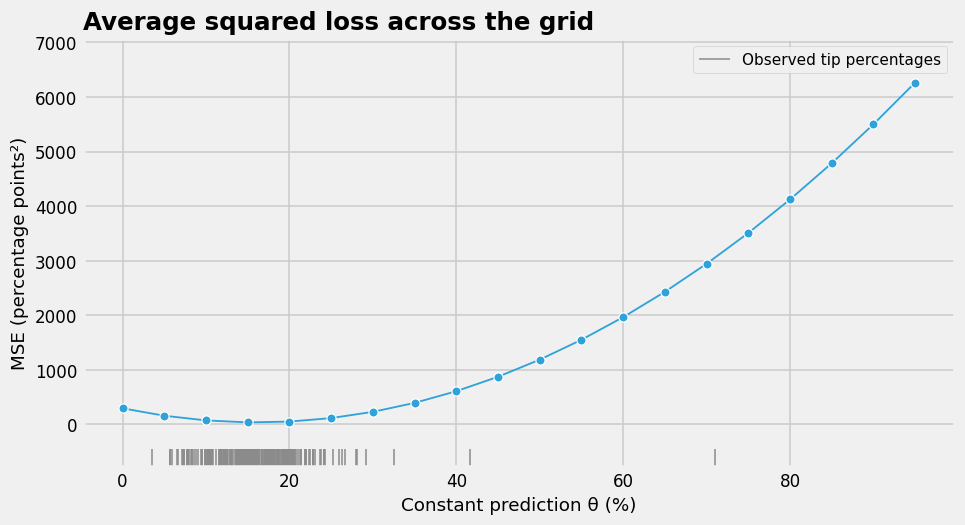

In [14]:
squared_loss_optimum = brute_force_optimize(
    squared_loss, tips['tip_pct'].to_numpy(), np.arange(0, 100, 5))
utils.plot_average_loss(tips['tip_pct'], squared_loss_optimum, squared=True, coarse=True)

<p>Takeaway: Average loss assigns a single score to a complete set of predictions. Compare candidates under the same loss and units.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="Brute-Force-Optimization"></a>
<a id="section6"></a><h2>6. Brute Force Optimization</h2><p>Question: how do the search range and spacing affect the selected prediction?</p>

<h3>Search a finer grid</h3><p>Reduce the spacing to 0.01 percentage points. The marked value is the best sampled candidate for each loss.</p>

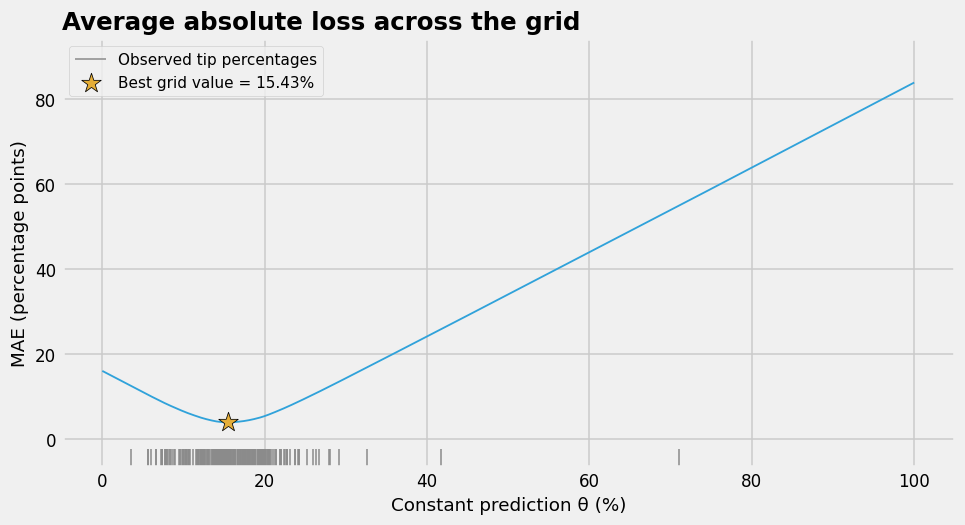

In [15]:
absolute_loss_optimum = brute_force_optimize(
    absolute_loss, tips['tip_pct'].to_numpy(), np.arange(0, 100, 0.01))
utils.plot_average_loss(tips['tip_pct'], absolute_loss_optimum, squared=False, optimum=True)

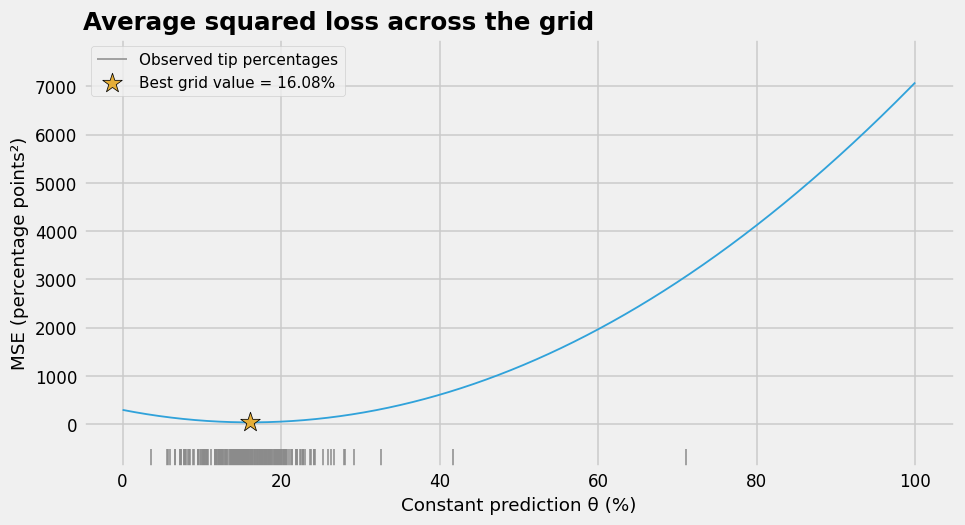

In [16]:
squared_loss_optimum = brute_force_optimize(
    squared_loss, tips['tip_pct'].to_numpy(), np.arange(0, 100, 0.01))
utils.plot_average_loss(tips['tip_pct'], squared_loss_optimum, squared=True, optimum=True)

<h3>Compare with the mean and median</h3><p>For a nonempty, equally weighted sample, the mean minimizes constant-model MSE. A median minimizes constant-model MAE. Grid spacing explains small numerical differences from these exact solutions.</p>

In [17]:
mean = np.mean(tips['tip_pct'])
median = np.median(tips['tip_pct'])
print(f'Mean tip percentage: {mean:.2f}%')
print(f'Median tip percentage: {median:.2f}%')

Mean tip percentage: 16.08%
Median tip percentage: 15.43%


<h3>Use a coarser range</h3><p>Restore a coarse grid with ten-percentage-point spacing. More widely spaced candidates miss the exact mean even when the search range covers the solution.</p>

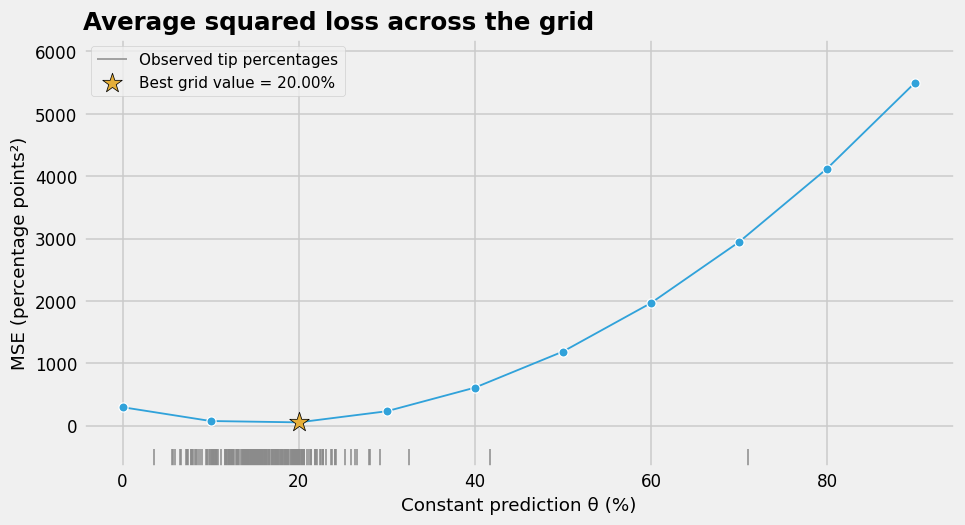

In [18]:
squared_loss_optimum = brute_force_optimize(
    squared_loss, tips['tip_pct'].to_numpy(), np.arange(0, 100, 10))
utils.plot_average_loss(tips['tip_pct'], squared_loss_optimum, squared=True, optimum=True, coarse=True)

<p>Takeaway: A grid search is limited by its range and resolution. The mean and median provide direct checks for this constant-model problem.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="lecture-summary"></a><h2>Lecture summary</h2><ul><li>Loss specifies the cost of a prediction error.</li><li>Average loss scores one model on the observed sample.</li><li>Constant-model MSE selects the mean and MAE selects a median.</li><li>Grid resolution limits numerical precision.</li><li>A low fitting loss alone does not establish performance on future bills.</li></ul>

<a id="section7"></a><h2>7. Individual errors and the loss minimum</h2><p>Optional extension.</p><p>Question: which observations contribute most to the objective?</p>

<h3>Inspect a small worked example</h3><p>Use five illustrative values so every residual is visible. The prediction is fixed at 22. The last column grows especially quickly for distant observations.</p>

In [19]:
small = np.array([20, 21, 22, 29, 33])
theta = 22
errors = small - theta
contributions = pd.DataFrame({'observed': small, 'residual': errors,
    'absolute_error': np.abs(errors), 'squared_error': errors**2})
contributions

,observed,residual,absolute_error,squared_error
0,20,-2,2,4
1,21,-1,1,1
2,22,0,0,0
3,29,7,7,49
4,33,11,11,121


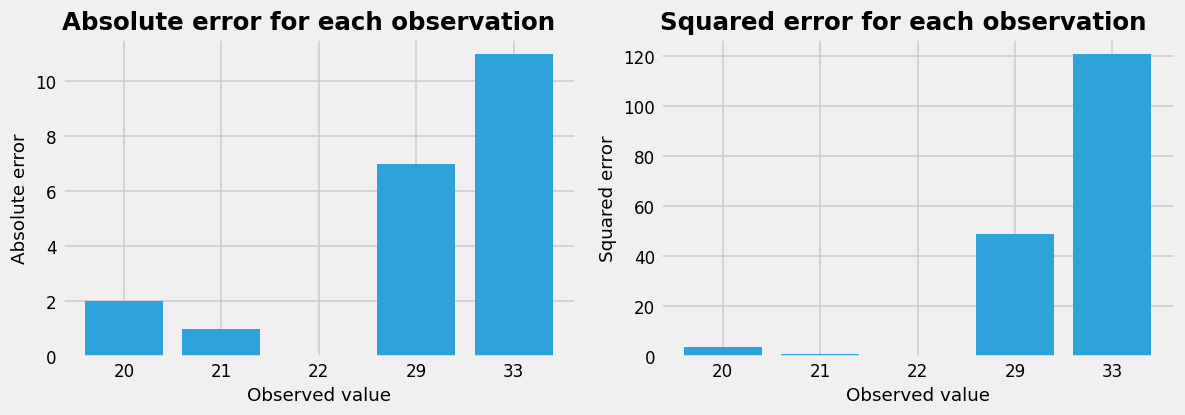

In [20]:
utils.plot_loss_contributions(contributions)

<p>The largest residual contributes 11 units to absolute loss and 121 squared units to squared loss. Averaging these columns gives MAE and MSE.</p>

<h3>Read the two objective shapes</h3><p>Calculate both average losses over a fine grid. The MAE curve changes slope at each observation. The MSE curve is smooth.</p>

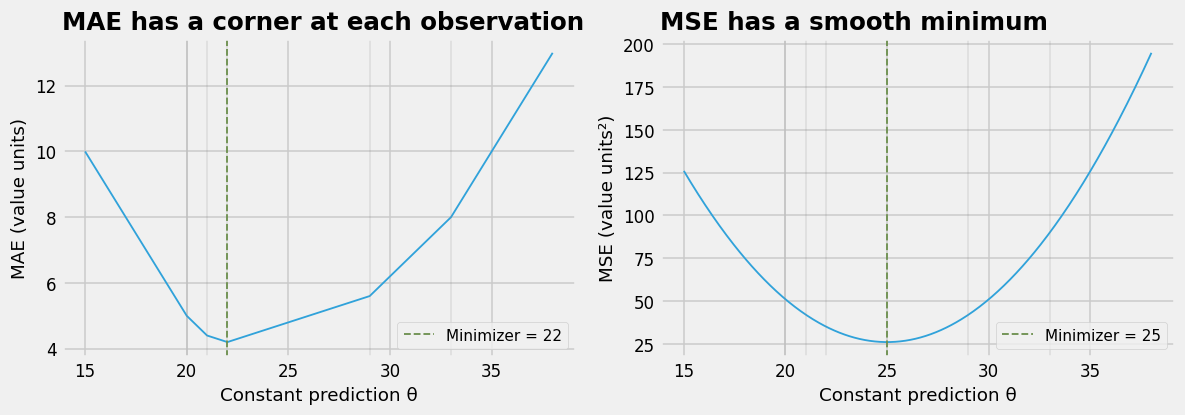

In [21]:
grid = np.linspace(15, 38, 461)
mae_curve = [absolute_loss(small, t) for t in grid]
mse_curve = [squared_loss(small, t) for t in grid]
utils.plot_small_losses(grid, mae_curve, mse_curve, small, small.mean(), np.median(small))

<h3>Find a non-unique MAE solution</h3><p>With four values, every prediction between the two middle observations gives the same minimum MAE. NumPy reports their midpoint as the sample median.</p>

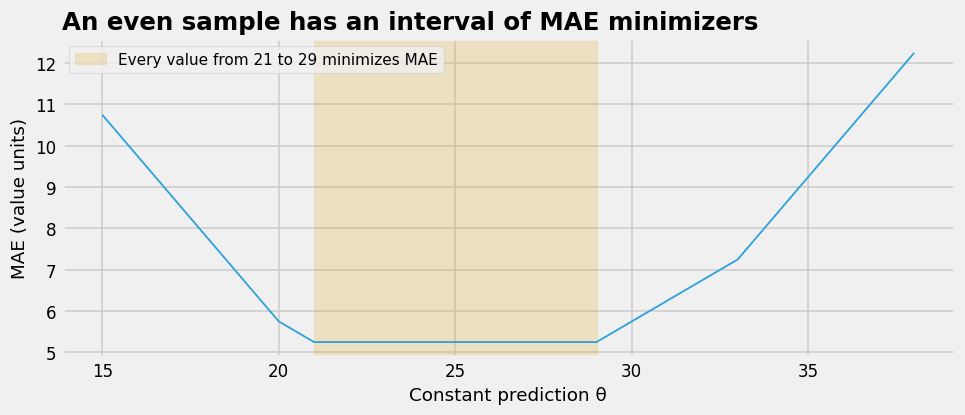

In [22]:
even_data = np.array([20, 21, 29, 33])
middle = np.sort(even_data)[1:3]
mae_even = [absolute_loss(even_data, t) for t in grid]
utils.plot_flat_minimum(grid, mae_even, middle)

<p>Takeaway: The minimum follows from the full set of residuals. MAE is convex but its minimizer is not always unique.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="section8"></a><h2>8. Sensitivity to an extreme observation</h2><p>Optional extension.</p><p>Question: how much does one added observation change the fitted constant?</p>

<h3>Vary one added bill</h3><p>Keep the recorded tips fixed and append one constructed percentage at a time. A value of 300% is a stress case, rather than a correction to the recorded data. An unusual observation requires investigation before removal.</p>

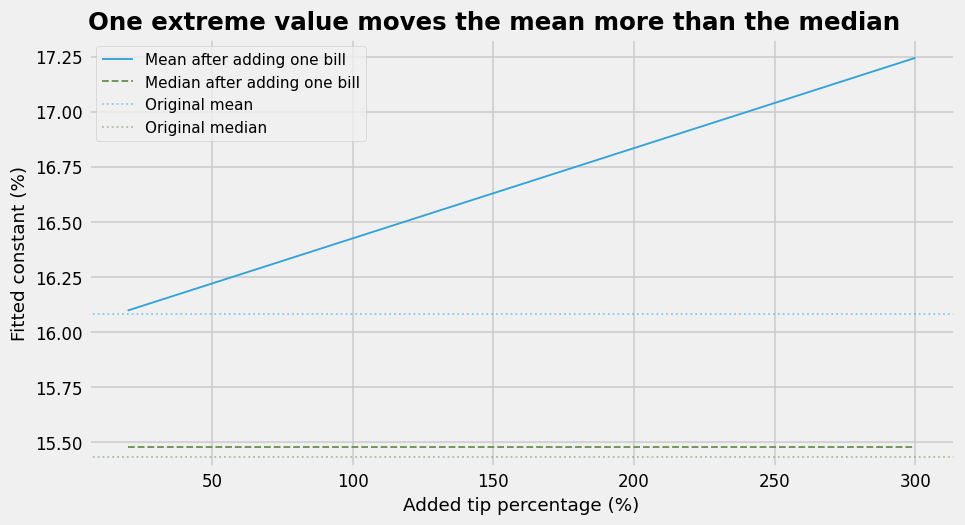

In [23]:
y = tips['tip_pct'].to_numpy()
added_values = np.linspace(20, 300, 100)
means = [np.append(y, value).mean() for value in added_values]
medians = [np.median(np.append(y, value)) for value in added_values]
utils.plot_sensitivity(added_values, means, medians, y.mean(), np.median(y))

<p>The mean moves steadily as the added percentage increases. The median changes much less because its position depends mainly on ordering.</p>

In [24]:
with_extreme = np.append(y, 300.0)
print(f'Mean: {y.mean():.2f}% -> {with_extreme.mean():.2f}%')
print(f'Median: {np.median(y):.2f}% -> {np.median(with_extreme):.2f}%')

Mean: 16.08% -> 17.24%
Median: 15.43% -> 15.48%


<p>Takeaway: Sensitivity describes a property of the loss. The plot does not establish whether an extreme observation is erroneous or unimportant.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>

<a id="section9"></a><h2>9. Error costs in repair planning</h2><p>Optional extension.</p><p>Question: what changes when underestimating a repair duration costs more than overestimating?</p>

<h3>Load constructed maintenance durations</h3><p>The local file contains 12 invented repair jobs in minutes, including one long job. Use one planned duration for all jobs to isolate the loss choice. This is a teaching scenario without operational cost estimates.</p>

In [25]:
repairs = pd.read_csv('illustrative_repair_durations.csv')
durations = repairs['duration_min'].to_numpy()
repairs.head()

,job_id,duration_min
0,1,18
1,2,22
2,3,24
3,4,25
4,5,26


<h3>Write the asymmetric cost</h3><p>An underestimate costs three illustrative units per missed minute. An overestimate costs one unit per unused minute. The asymmetry changes the decision without changing the observations.</p>

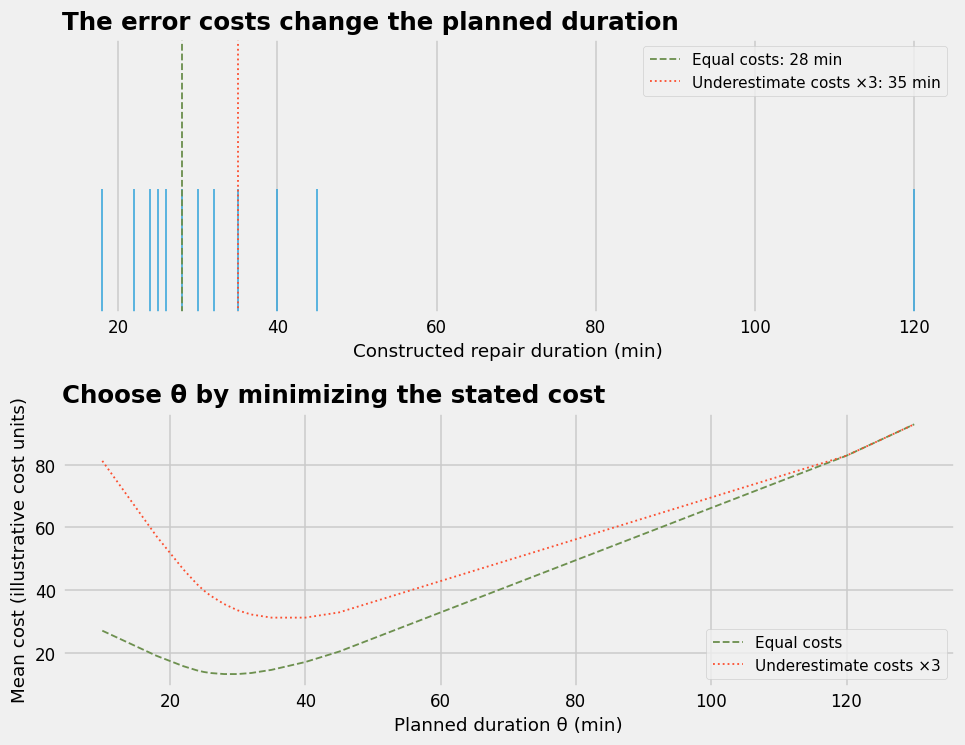

In [26]:
def planning_loss(observed, planned, underestimate_cost=3):
    residual = observed - planned
    costs = np.where(residual > 0, underestimate_cost * residual, -residual)
    return costs.mean()

plans = np.arange(10, 131, 1)
equal_cost = [planning_loss(durations, t, 1) for t in plans]
unequal_cost = [planning_loss(durations, t, 3) for t in plans]
best_equal = plans[np.argmin(equal_cost)]
best_unequal = plans[np.argmin(unequal_cost)]
utils.plot_planning_losses(durations, plans, equal_cost, unequal_cost, best_equal, best_unequal)

<p>The threefold underestimate penalty selects a longer planned duration. Several grid values tie at the minimum here. The search selects the first minimum, so the displayed plan is one optimal choice.</p>

<p>Takeaway: The loss encodes the decision. Changing error costs changes the preferred prediction even with the same data and model.</p><p><a href="#lecture-structure">Back to Lecture Structure</a></p>